# Phase 03 — Psychological Capital → Employability

## Step 03 — Descriptive Statistics

මෙම notebook එකේ අරමුණ වන්නේ Phase 03 Psychological Capital සහ Employability දත්තවල මූලික සංඛ්‍යානමය ලක්ෂණ විස්තර කිරීමයි.

මෙහිදී පහත කරුණු විශ්ලේෂණය කරයි:

- Mean
- Median
- Standard Deviation
- Minimum සහ Maximum
- Interquartile Range (IQR)
- Skewness
- Kurtosis
- Mean සඳහා 95% Confidence Interval
- Histogram මගින් distribution පරීක්ෂා කිරීම
- Boxplot මගින් variability සහ potential outliers පරීක්ෂා කිරීම
- Psychological Capital constructs අතර descriptive comparison එකක් කිරීම
- Demographic variables සඳහා frequency සහ percentage summary එකක් සකස් කිරීම

මෙම පියවරේදී predictive model එක train නොකරයි.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "phase3_psycap":
    PROJECT_DIR = PROJECT_DIR.parent.parent

DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "phase3_psycap_prepared.csv"
)

REPORT_DIR = (
    PROJECT_DIR
    / "reports"
    / "phase3"
    / "descriptive"
)

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("PROJECT_DIR:", PROJECT_DIR)
print("DATA_PATH:", DATA_PATH)
print("REPORT_DIR:", REPORT_DIR)

PROJECT_DIR: d:\internship-employability-project
DATA_PATH: d:\internship-employability-project\data\processed\phase3_psycap_prepared.csv
REPORT_DIR: d:\internship-employability-project\reports\phase3\descriptive


In [3]:
df = pd.read_csv(
    DATA_PATH
)

print(
    "Dataset shape:",
    df.shape
)

df.head()

Dataset shape: (1000, 41)


,Response_ID,Gender,Age,Degree Program,Internship Status,PsyCap1,PsyCap2,PsyCap3,PsyCap4,PsyCap5,...,Optimism_avg,Resilience_avg,SelfEfficacy_avg,PsyCap_avg,HumanCapital_avg,SocialCapital_avg,CareerIdentity_avg,EnvironmentalMonitoring_avg,Balance_avg,EVS_avg
0,1,Female,18–20,Information Technology,Yes,5,4,4,4,5,...,4.333333,4.000000,3.666667,4.083333,5.000000,4.0,4.75,5.0,5.0,4.750000
1,2,Female,21–23,Business Management,Yes,3,5,5,4,4,...,4.000000,3.666667,3.666667,3.916667,3.666667,3.5,3.75,4.0,2.5,3.500000
2,3,Male,18–20,Information Technology,Yes,4,5,4,5,4,...,4.333333,3.333333,3.333333,3.833333,3.666667,4.0,3.75,4.0,3.5,3.750000
3,4,Male,18–20,Engineering,Yes,4,4,4,4,4,...,4.000000,4.000000,4.000000,4.000000,4.000000,4.0,4.00,4.0,4.0,4.000000
4,5,Male,21–23,Business Management,Yes,3,3,5,3,5,...,4.000000,3.666667,3.333333,3.666667,4.000000,4.5,4.50,5.0,4.0,4.333333


## විශ්ලේෂණයට භාවිත කරන Constructs

Psychological Capital සඳහා පහත constructs භාවිත කරයි:

- Hope
- Optimism
- Resilience
- Self-Efficacy
- Overall Psychological Capital

Employability සඳහා ප්‍රධාන target construct එක `EVS_avg` ලෙස භාවිත කරයි.

අමතරව Employability subconstructs ද descriptive analysis සඳහා සලකා බලයි.

In [4]:
PSYCAP_CONSTRUCTS = [
    "Hope_avg",
    "Optimism_avg",
    "Resilience_avg",
    "SelfEfficacy_avg",
    "PsyCap_avg"
]

EVS_CONSTRUCTS = [
    "HumanCapital_avg",
    "SocialCapital_avg",
    "CareerIdentity_avg",
    "EnvironmentalMonitoring_avg",
    "Balance_avg",
    "EVS_avg"
]

MAIN_CONSTRUCTS = (
    PSYCAP_CONSTRUCTS
    +
    ["EVS_avg"]
)

ALL_CONSTRUCTS = (
    PSYCAP_CONSTRUCTS
    +
    EVS_CONSTRUCTS
)

Validate Required Columns

In [5]:
missing_columns = [
    column
    for column in ALL_CONSTRUCTS
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required construct columns: {missing_columns}"
    )

print(
    "All required construct columns are available."
)

All required construct columns are available.


Basic Descriptive Statistics

In [6]:
basic_descriptive = (
    df[ALL_CONSTRUCTS]
    .describe()
    .T
)

basic_descriptive

,count,mean,std,min,25%,50%,75%,max
Hope_avg,1000.0,4.236000,0.396674,1.000000,4.0,4.333333,4.333333,5.0
Optimism_avg,1000.0,4.271667,0.425101,1.000000,4.0,4.333333,4.333333,5.0
Resilience_avg,1000.0,4.141000,0.414678,1.333333,4.0,4.333333,4.333333,5.0
SelfEfficacy_avg,1000.0,4.139667,0.430130,1.333333,4.0,4.000000,4.333333,5.0
PsyCap_avg,1000.0,4.197083,0.361273,1.333333,4.0,4.250000,4.333333,5.0
HumanCapital_avg,1000.0,3.943000,0.367722,1.000000,4.0,4.000000,4.000000,5.0
SocialCapital_avg,1000.0,3.893000,0.437313,1.000000,4.0,4.000000,4.000000,5.0
CareerIdentity_avg,1000.0,4.358000,0.529969,1.000000,4.0,4.250000,4.750000,5.0
EnvironmentalMonitoring_avg,1000.0,3.971000,0.440855,1.000000,4.0,4.000000,4.000000,5.0
Balance_avg,1000.0,3.991000,0.413630,1.000000,4.0,4.000000,4.000000,5.0


Create Research-Friendly Descriptive Table

In [7]:
descriptive_summary = pd.DataFrame({

    "N": (
        df[ALL_CONSTRUCTS]
        .count()
    ),

    "Mean": (
        df[ALL_CONSTRUCTS]
        .mean()
    ),

    "Median": (
        df[ALL_CONSTRUCTS]
        .median()
    ),

    "Std_Dev": (
        df[ALL_CONSTRUCTS]
        .std()
    ),

    "Minimum": (
        df[ALL_CONSTRUCTS]
        .min()
    ),

    "Maximum": (
        df[ALL_CONSTRUCTS]
        .max()
    ),

    "Q1": (
        df[ALL_CONSTRUCTS]
        .quantile(
            0.25
        )
    ),

    "Q3": (
        df[ALL_CONSTRUCTS]
        .quantile(
            0.75
        )
    )
})

descriptive_summary[
    "IQR"
] = (
    descriptive_summary[
        "Q3"
    ]
    -
    descriptive_summary[
        "Q1"
    ]
)

descriptive_summary

,N,Mean,Median,Std_Dev,Minimum,Maximum,Q1,Q3,IQR
Hope_avg,1000,4.236000,4.333333,0.396674,1.000000,5.0,4.0,4.333333,0.333333
Optimism_avg,1000,4.271667,4.333333,0.425101,1.000000,5.0,4.0,4.333333,0.333333
Resilience_avg,1000,4.141000,4.333333,0.414678,1.333333,5.0,4.0,4.333333,0.333333
SelfEfficacy_avg,1000,4.139667,4.000000,0.430130,1.333333,5.0,4.0,4.333333,0.333333
PsyCap_avg,1000,4.197083,4.250000,0.361273,1.333333,5.0,4.0,4.333333,0.333333
HumanCapital_avg,1000,3.943000,4.000000,0.367722,1.000000,5.0,4.0,4.000000,0.000000
SocialCapital_avg,1000,3.893000,4.000000,0.437313,1.000000,5.0,4.0,4.000000,0.000000
CareerIdentity_avg,1000,4.358000,4.250000,0.529969,1.000000,5.0,4.0,4.750000,0.750000
EnvironmentalMonitoring_avg,1000,3.971000,4.000000,0.440855,1.000000,5.0,4.0,4.000000,0.000000
Balance_avg,1000,3.991000,4.000000,0.413630,1.000000,5.0,4.0,4.000000,0.000000


Skewness and Kurtosis

In [8]:
descriptive_summary[
    "Skewness"
] = (
    df[ALL_CONSTRUCTS]
    .skew()
)

descriptive_summary[
    "Kurtosis"
] = (
    df[ALL_CONSTRUCTS]
    .kurt()
)

descriptive_summary

,N,Mean,Median,Std_Dev,Minimum,Maximum,Q1,Q3,IQR,Skewness,Kurtosis
Hope_avg,1000,4.236000,4.333333,0.396674,1.000000,5.0,4.0,4.333333,0.333333,-2.653134,18.738701
Optimism_avg,1000,4.271667,4.333333,0.425101,1.000000,5.0,4.0,4.333333,0.333333,-2.589496,16.165332
Resilience_avg,1000,4.141000,4.333333,0.414678,1.333333,5.0,4.0,4.333333,0.333333,-2.166509,11.305464
SelfEfficacy_avg,1000,4.139667,4.000000,0.430130,1.333333,5.0,4.0,4.333333,0.333333,-1.369394,7.732062
PsyCap_avg,1000,4.197083,4.250000,0.361273,1.333333,5.0,4.0,4.333333,0.333333,-2.678727,17.866115
HumanCapital_avg,1000,3.943000,4.000000,0.367722,1.000000,5.0,4.0,4.000000,0.000000,-1.513868,10.457333
SocialCapital_avg,1000,3.893000,4.000000,0.437313,1.000000,5.0,4.0,4.000000,0.000000,-1.675395,8.309782
CareerIdentity_avg,1000,4.358000,4.250000,0.529969,1.000000,5.0,4.0,4.750000,0.750000,-1.319121,5.550920
EnvironmentalMonitoring_avg,1000,3.971000,4.000000,0.440855,1.000000,5.0,4.0,4.000000,0.000000,-1.686673,10.675662
Balance_avg,1000,3.991000,4.000000,0.413630,1.000000,5.0,4.0,4.000000,0.000000,-1.964888,13.097516


Add Simple Distribution Flags

In [9]:
def distribution_flag(
    skewness,
    kurtosis
):

    if (
        abs(skewness) <= 1
        and
        abs(kurtosis) <= 3
    ):
        return "Generally Acceptable"

    return "Review Distribution"


descriptive_summary[
    "Distribution_Check"
] = [

    distribution_flag(
        row["Skewness"],
        row["Kurtosis"]
    )

    for _, row
    in descriptive_summary.iterrows()
]

descriptive_summary

,N,Mean,Median,Std_Dev,Minimum,Maximum,Q1,Q3,IQR,Skewness,Kurtosis,Distribution_Check
Hope_avg,1000,4.236000,4.333333,0.396674,1.000000,5.0,4.0,4.333333,0.333333,-2.653134,18.738701,Review Distribution
Optimism_avg,1000,4.271667,4.333333,0.425101,1.000000,5.0,4.0,4.333333,0.333333,-2.589496,16.165332,Review Distribution
Resilience_avg,1000,4.141000,4.333333,0.414678,1.333333,5.0,4.0,4.333333,0.333333,-2.166509,11.305464,Review Distribution
SelfEfficacy_avg,1000,4.139667,4.000000,0.430130,1.333333,5.0,4.0,4.333333,0.333333,-1.369394,7.732062,Review Distribution
PsyCap_avg,1000,4.197083,4.250000,0.361273,1.333333,5.0,4.0,4.333333,0.333333,-2.678727,17.866115,Review Distribution
HumanCapital_avg,1000,3.943000,4.000000,0.367722,1.000000,5.0,4.0,4.000000,0.000000,-1.513868,10.457333,Review Distribution
SocialCapital_avg,1000,3.893000,4.000000,0.437313,1.000000,5.0,4.0,4.000000,0.000000,-1.675395,8.309782,Review Distribution
CareerIdentity_avg,1000,4.358000,4.250000,0.529969,1.000000,5.0,4.0,4.750000,0.750000,-1.319121,5.550920,Review Distribution
EnvironmentalMonitoring_avg,1000,3.971000,4.000000,0.440855,1.000000,5.0,4.0,4.000000,0.000000,-1.686673,10.675662,Review Distribution
Balance_avg,1000,3.991000,4.000000,0.413630,1.000000,5.0,4.0,4.000000,0.000000,-1.964888,13.097516,Review Distribution


## Mean සඳහා 95% Confidence Interval

Sample mean එකක් single value එකක් පමණක් ලෙස report කිරීම වෙනුවට, එම mean estimate එකේ uncertainty ද සලකා බලීම research reporting සඳහා වඩා ශක්තිමත් වේ.

එබැවින් constructs සඳහා approximate 95% confidence intervals ගණනය කරයි.

95% Confidence Interval Function

In [10]:
def mean_confidence_interval(
    series,
    confidence_z=1.96
):

    series = (
        series
        .dropna()
        .astype(float)
    )

    n = len(
        series
    )

    mean = (
        series.mean()
    )

    std = (
        series.std(
            ddof=1
        )
    )

    standard_error = (
        std
        /
        np.sqrt(
            n
        )
    )

    lower = (
        mean
        -
        confidence_z
        * standard_error
    )

    upper = (
        mean
        +
        confidence_z
        * standard_error
    )

    return (
        mean,
        standard_error,
        lower,
        upper
    )

Calculate 95% CI

In [11]:
confidence_results = []

for column in ALL_CONSTRUCTS:

    (
        mean,
        standard_error,
        lower,
        upper
    ) = mean_confidence_interval(
        df[column]
    )

    confidence_results.append({

        "Construct": column,

        "Mean": mean,

        "Standard_Error":
            standard_error,

        "CI_95_Lower":
            lower,

        "CI_95_Upper":
            upper
    })


confidence_interval_df = pd.DataFrame(
    confidence_results
)

confidence_interval_df

,Construct,Mean,Standard_Error,CI_95_Lower,CI_95_Upper
0,Hope_avg,4.236000,0.012544,4.211414,4.260586
1,Optimism_avg,4.271667,0.013443,4.245319,4.298015
2,Resilience_avg,4.141000,0.013113,4.115298,4.166702
3,SelfEfficacy_avg,4.139667,0.013602,4.113007,4.166326
4,PsyCap_avg,4.197083,0.011424,4.174691,4.219475
5,HumanCapital_avg,3.943000,0.011628,3.920208,3.965792
6,SocialCapital_avg,3.893000,0.013829,3.865895,3.920105
7,CareerIdentity_avg,4.358000,0.016759,4.325152,4.390848
8,EnvironmentalMonitoring_avg,3.971000,0.013941,3.943676,3.998324
9,Balance_avg,3.991000,0.013080,3.965363,4.016637


Merge Descriptive + CI Results

In [12]:
final_descriptive_table = (

    descriptive_summary

    .reset_index()

    .rename(
        columns={
            "index":
                "Construct"
        }
    )

    .merge(
        confidence_interval_df,
        on="Construct",
        how="left",
        suffixes=(
            "",
            "_CI"
        )
    )
)

final_descriptive_table

,Construct,N,Mean,Median,Std_Dev,Minimum,Maximum,Q1,Q3,IQR,Skewness,Kurtosis,Distribution_Check,Mean_CI,Standard_Error,CI_95_Lower,CI_95_Upper
0,Hope_avg,1000,4.236000,4.333333,0.396674,1.000000,5.0,4.0,4.333333,0.333333,-2.653134,18.738701,Review Distribution,4.236000,0.012544,4.211414,4.260586
1,Optimism_avg,1000,4.271667,4.333333,0.425101,1.000000,5.0,4.0,4.333333,0.333333,-2.589496,16.165332,Review Distribution,4.271667,0.013443,4.245319,4.298015
2,Resilience_avg,1000,4.141000,4.333333,0.414678,1.333333,5.0,4.0,4.333333,0.333333,-2.166509,11.305464,Review Distribution,4.141000,0.013113,4.115298,4.166702
3,SelfEfficacy_avg,1000,4.139667,4.000000,0.430130,1.333333,5.0,4.0,4.333333,0.333333,-1.369394,7.732062,Review Distribution,4.139667,0.013602,4.113007,4.166326
4,PsyCap_avg,1000,4.197083,4.250000,0.361273,1.333333,5.0,4.0,4.333333,0.333333,-2.678727,17.866115,Review Distribution,4.197083,0.011424,4.174691,4.219475
5,HumanCapital_avg,1000,3.943000,4.000000,0.367722,1.000000,5.0,4.0,4.000000,0.000000,-1.513868,10.457333,Review Distribution,3.943000,0.011628,3.920208,3.965792
6,SocialCapital_avg,1000,3.893000,4.000000,0.437313,1.000000,5.0,4.0,4.000000,0.000000,-1.675395,8.309782,Review Distribution,3.893000,0.013829,3.865895,3.920105
7,CareerIdentity_avg,1000,4.358000,4.250000,0.529969,1.000000,5.0,4.0,4.750000,0.750000,-1.319121,5.550920,Review Distribution,4.358000,0.016759,4.325152,4.390848
8,EnvironmentalMonitoring_avg,1000,3.971000,4.000000,0.440855,1.000000,5.0,4.0,4.000000,0.000000,-1.686673,10.675662,Review Distribution,3.971000,0.013941,3.943676,3.998324
9,Balance_avg,1000,3.991000,4.000000,0.413630,1.000000,5.0,4.0,4.000000,0.000000,-1.964888,13.097516,Review Distribution,3.991000,0.013080,3.965363,4.016637


PsyCap Main Construct Summary

In [13]:
psycap_main_summary = (

    final_descriptive_table[
        final_descriptive_table[
            "Construct"
        ]
        .isin(
            MAIN_CONSTRUCTS
        )
    ]

    .copy()
)

psycap_main_summary[
    [
        "Construct",
        "Mean",
        "Median",
        "Std_Dev",
        "Minimum",
        "Maximum",
        "Skewness",
        "Kurtosis",
        "CI_95_Lower",
        "CI_95_Upper"
    ]
]

,Construct,Mean,Median,Std_Dev,Minimum,Maximum,Skewness,Kurtosis,CI_95_Lower,CI_95_Upper
0,Hope_avg,4.236000,4.333333,0.396674,1.000000,5.0,-2.653134,18.738701,4.211414,4.260586
1,Optimism_avg,4.271667,4.333333,0.425101,1.000000,5.0,-2.589496,16.165332,4.245319,4.298015
2,Resilience_avg,4.141000,4.333333,0.414678,1.333333,5.0,-2.166509,11.305464,4.115298,4.166702
3,SelfEfficacy_avg,4.139667,4.000000,0.430130,1.333333,5.0,-1.369394,7.732062,4.113007,4.166326
4,PsyCap_avg,4.197083,4.250000,0.361273,1.333333,5.0,-2.678727,17.866115,4.174691,4.219475
10,EVS_avg,4.083333,4.083333,0.357211,1.000000,5.0,-1.994620,12.015137,4.061193,4.105474


Rank PsyCap Constructs by Mean

In [14]:
psycap_construct_comparison = (

    final_descriptive_table[
        final_descriptive_table[
            "Construct"
        ]
        .isin(
            [
                "Hope_avg",
                "Optimism_avg",
                "Resilience_avg",
                "SelfEfficacy_avg"
            ]
        )
    ]

    .sort_values(
        "Mean",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)

psycap_construct_comparison[
    "Rank"
] = (
    np.arange(
        1,
        len(
            psycap_construct_comparison
        )
        + 1
    )
)

psycap_construct_comparison[
    [
        "Rank",
        "Construct",
        "Mean",
        "Std_Dev",
        "CI_95_Lower",
        "CI_95_Upper"
    ]
]

,Rank,Construct,Mean,Std_Dev,CI_95_Lower,CI_95_Upper
0,1,Optimism_avg,4.271667,0.425101,4.245319,4.298015
1,2,Hope_avg,4.236000,0.396674,4.211414,4.260586
2,3,Resilience_avg,4.141000,0.414678,4.115298,4.166702
3,4,SelfEfficacy_avg,4.139667,0.430130,4.113007,4.166326


Histogram for Main Constructs

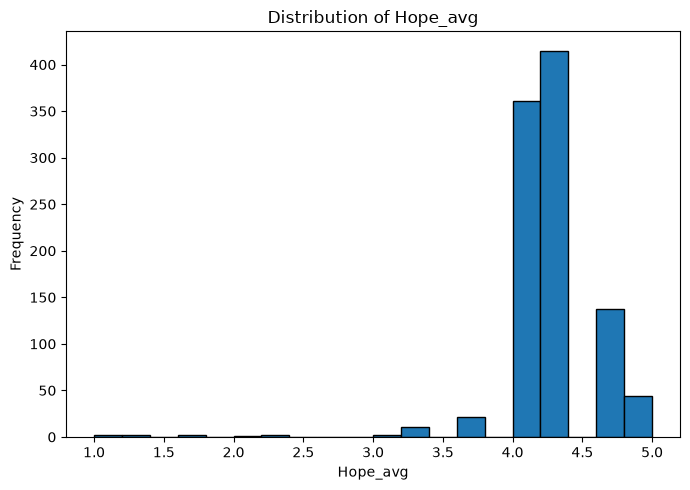

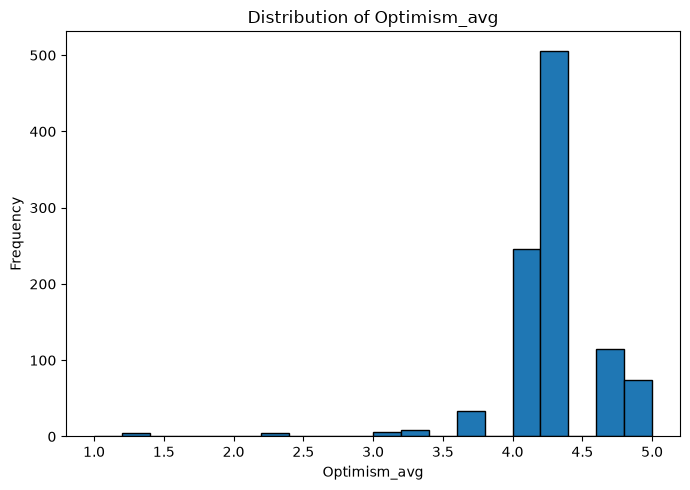

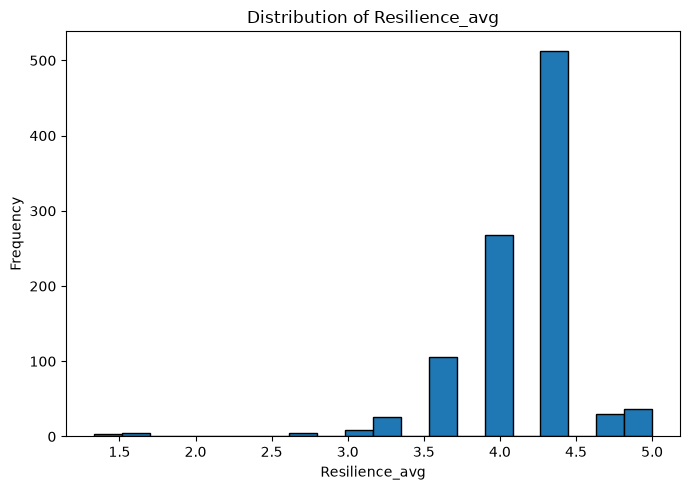

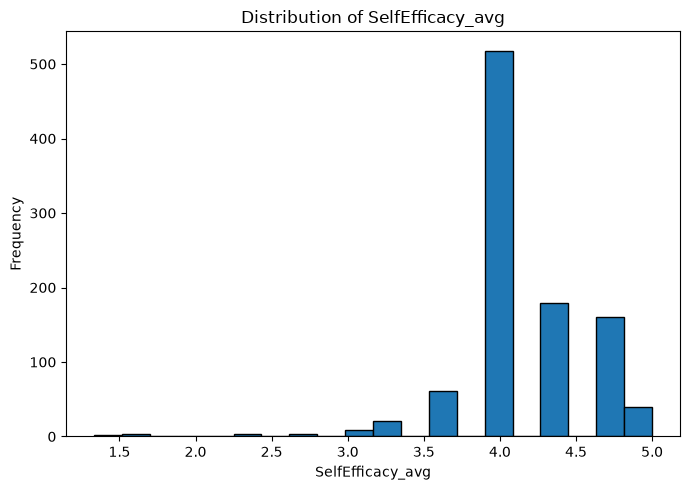

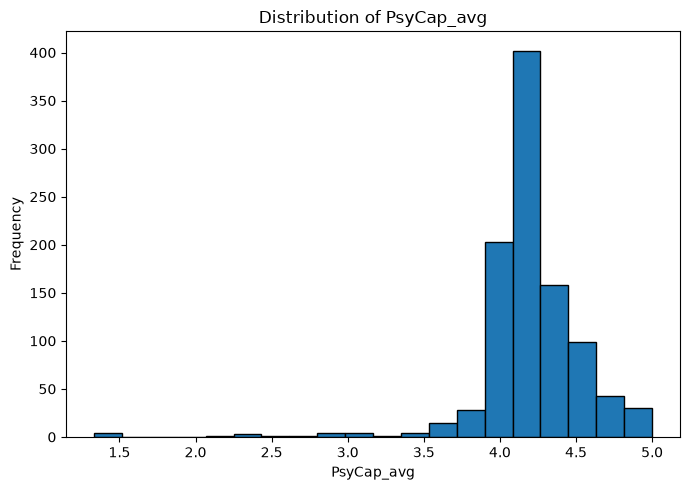

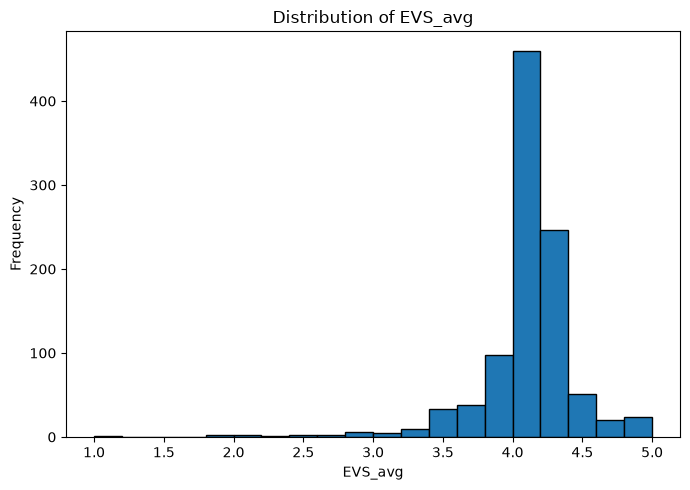

In [15]:
for column in MAIN_CONSTRUCTS:

    plt.figure(
        figsize=(7, 5)
    )

    plt.hist(
        df[column],
        bins=20,
        edgecolor="black"
    )

    plt.xlabel(
        column
    )

    plt.ylabel(
        "Frequency"
    )

    plt.title(
        f"Distribution of {column}"
    )

    plt.tight_layout()

    plt.savefig(
        REPORT_DIR
        / f"{column}_Histogram.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

Boxplots

C:\Users\User\AppData\Local\Temp\ipykernel_23080\1245520361.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


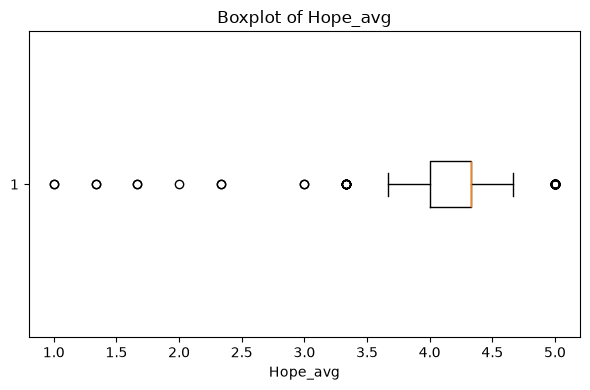

C:\Users\User\AppData\Local\Temp\ipykernel_23080\1245520361.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


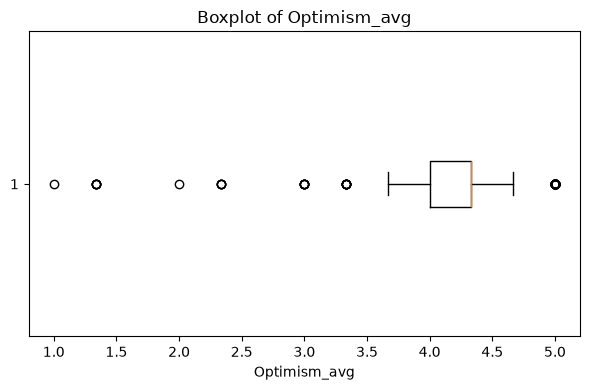

C:\Users\User\AppData\Local\Temp\ipykernel_23080\1245520361.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


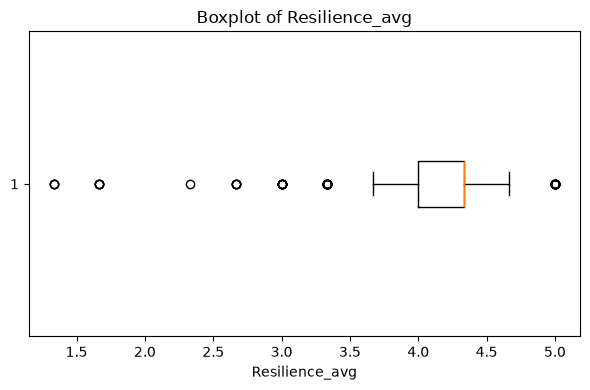

C:\Users\User\AppData\Local\Temp\ipykernel_23080\1245520361.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


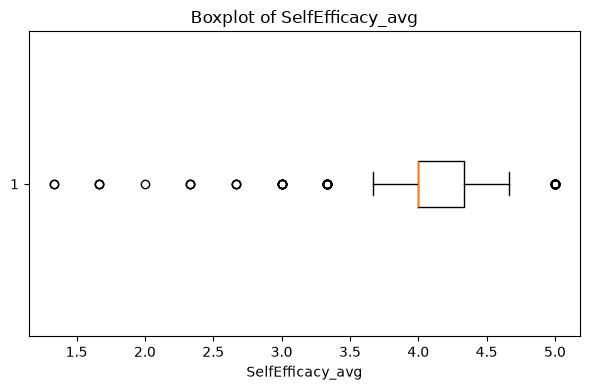

C:\Users\User\AppData\Local\Temp\ipykernel_23080\1245520361.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


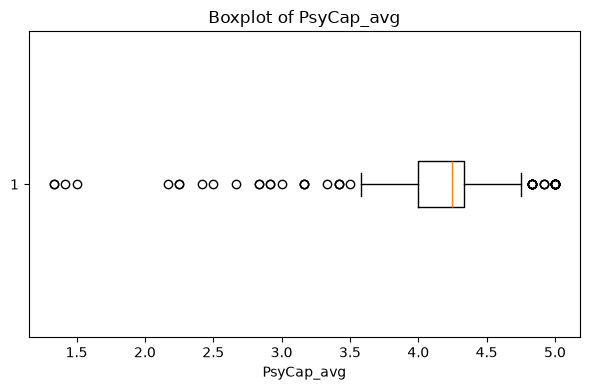

C:\Users\User\AppData\Local\Temp\ipykernel_23080\1245520361.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


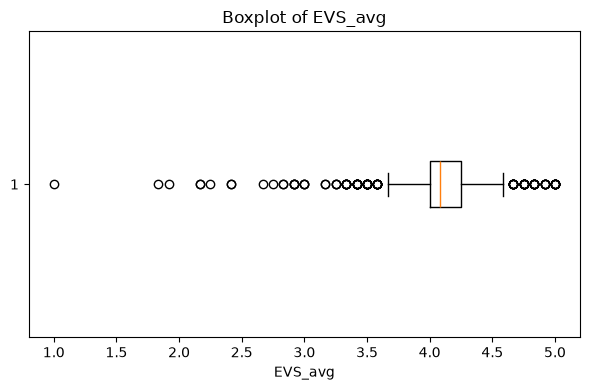

In [16]:
for column in MAIN_CONSTRUCTS:

    plt.figure(
        figsize=(6, 4)
    )

    plt.boxplot(
        df[column],
        vert=False
    )

    plt.xlabel(
        column
    )

    plt.title(
        f"Boxplot of {column}"
    )

    plt.tight_layout()

    plt.savefig(
        REPORT_DIR
        / f"{column}_Boxplot.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

Outlier Diagnostic Using IQR

In [17]:
outlier_summary = []

for column in MAIN_CONSTRUCTS:

    q1 = (
        df[column]
        .quantile(
            0.25
        )
    )

    q3 = (
        df[column]
        .quantile(
            0.75
        )
    )

    iqr = (
        q3
        -
        q1
    )

    lower_bound = (
        q1
        -
        1.5
        * iqr
    )

    upper_bound = (
        q3
        +
        1.5
        * iqr
    )

    outlier_count = (
        (
            (
                df[column]
                <
                lower_bound
            )
            |
            (
                df[column]
                >
                upper_bound
            )
        )
        .sum()
    )

    outlier_summary.append({

        "Construct": column,

        "Lower_Bound":
            lower_bound,

        "Upper_Bound":
            upper_bound,

        "Potential_Outliers":
            int(
                outlier_count
            ),

        "Percentage":
            float(
                outlier_count
                /
                len(df)
                *
                100
            )
    })


outlier_summary_df = pd.DataFrame(
    outlier_summary
)

outlier_summary_df

,Construct,Lower_Bound,Upper_Bound,Potential_Outliers,Percentage
0,Hope_avg,3.500,4.833333,66,6.6
1,Optimism_avg,3.500,4.833333,99,9.9
2,Resilience_avg,3.500,4.833333,83,8.3
3,SelfEfficacy_avg,3.500,4.833333,82,8.2
4,PsyCap_avg,3.500,4.833333,53,5.3
5,EVS_avg,3.625,4.625000,108,10.8


Sinhala explanation

Potential outliers තිබ්බොත් ඒවා automatically remove කරන්න එපා.

Likert-based behavioral data වල genuine low/high respondents වෙන්න පුළුවන්.

Validate Construct Ranges Again

In [18]:
range_validation = []

for column in ALL_CONSTRUCTS:

    minimum = (
        df[column]
        .min()
    )

    maximum = (
        df[column]
        .max()
    )

    valid = (
        minimum >= 1
        and
        maximum <= 5
    )

    range_validation.append({

        "Construct":
            column,

        "Minimum":
            minimum,

        "Maximum":
            maximum,

        "Within_1_to_5":
            valid
    })


range_validation_df = pd.DataFrame(
    range_validation
)

range_validation_df

,Construct,Minimum,Maximum,Within_1_to_5
0,Hope_avg,1.000000,5.0,True
1,Optimism_avg,1.000000,5.0,True
2,Resilience_avg,1.333333,5.0,True
3,SelfEfficacy_avg,1.333333,5.0,True
4,PsyCap_avg,1.333333,5.0,True
5,HumanCapital_avg,1.000000,5.0,True
6,SocialCapital_avg,1.000000,5.0,True
7,CareerIdentity_avg,1.000000,5.0,True
8,EnvironmentalMonitoring_avg,1.000000,5.0,True
9,Balance_avg,1.000000,5.0,True


## Demographic Descriptive Summary

Demographic variables සඳහා mean හෝ standard deviation භාවිත කිරීම සුදුසු නොවන බැවින්, frequency සහ percentage මගින් summary එකක් සකස් කරයි.

මෙම demographic variables ප්‍රධාන PsyCap prediction model එකට automatically ඇතුළත් නොකරයි.

Define Demographics

In [19]:
DEMOGRAPHIC_COLUMNS = [
    "Gender",
    "Age",
    "Degree Program",
    "Internship Status"
]

Demographic Frequency and Percentage

In [20]:
demographic_summary = []

for column in DEMOGRAPHIC_COLUMNS:

    counts = (
        df[column]
        .value_counts(
            dropna=False
        )
    )

    percentages = (
        df[column]
        .value_counts(
            normalize=True,
            dropna=False
        )
        * 100
    )

    for category in counts.index:

        demographic_summary.append({

            "Variable":
                column,

            "Category":
                category,

            "Count":
                int(
                    counts[
                        category
                    ]
                ),

            "Percentage":
                float(
                    percentages[
                        category
                    ]
                )
        })


demographic_summary_df = pd.DataFrame(
    demographic_summary
)

demographic_summary_df

,Variable,Category,Count,Percentage
0,Gender,Female,515,51.5
1,Gender,Male,454,45.4
2,Gender,Prefer not to say,31,3.1
3,Age,21–23,543,54.3
4,Age,18–20,215,21.5
5,Age,24–26,192,19.2
6,Age,27 or above,50,5.0
7,Degree Program,Information Technology,552,55.2
8,Degree Program,Business Management,207,20.7
9,Degree Program,Engineering,143,14.3


Sample Demographic Bar Charts

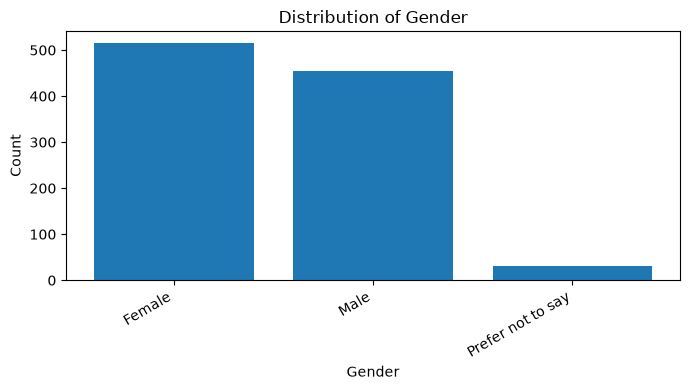

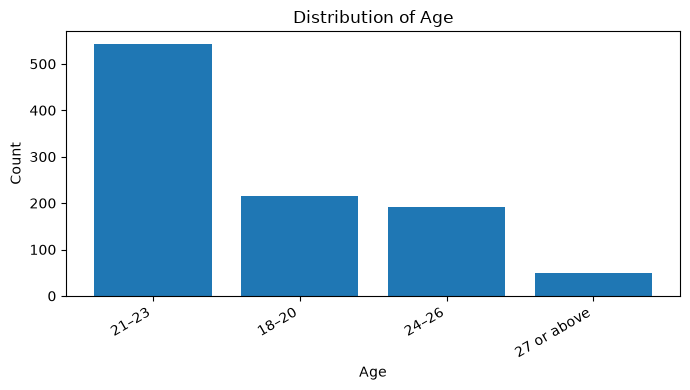

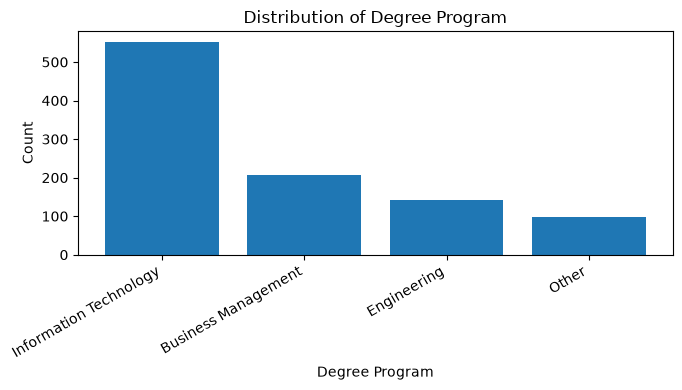

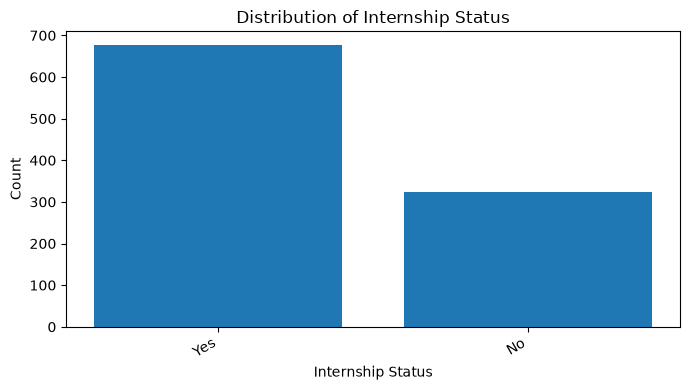

In [21]:
for column in DEMOGRAPHIC_COLUMNS:

    counts = (
        df[column]
        .value_counts()
    )

    plt.figure(
        figsize=(7, 4)
    )

    plt.bar(
        counts.index.astype(str),
        counts.values
    )

    plt.xlabel(
        column
    )

    plt.ylabel(
        "Count"
    )

    plt.title(
        f"Distribution of {column}"
    )

    plt.xticks(
        rotation=30,
        ha="right"
    )

    plt.tight_layout()

    plt.savefig(
        REPORT_DIR
        / f"{column.replace(' ', '_')}_Distribution.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

Important Data Source Check

In [22]:
if "data_source" in df.columns:

    data_source_summary = (

        df[
            "data_source"
        ]

        .value_counts(
            dropna=False
        )

        .rename_axis(
            "Data_Source"
        )

        .reset_index(
            name="Count"
        )
    )

    data_source_summary[
        "Percentage"
    ] = (

        data_source_summary[
            "Count"
        ]

        /
        len(df)

        *
        100
    )

    data_source_summary

Construct Mean Comparison Plot

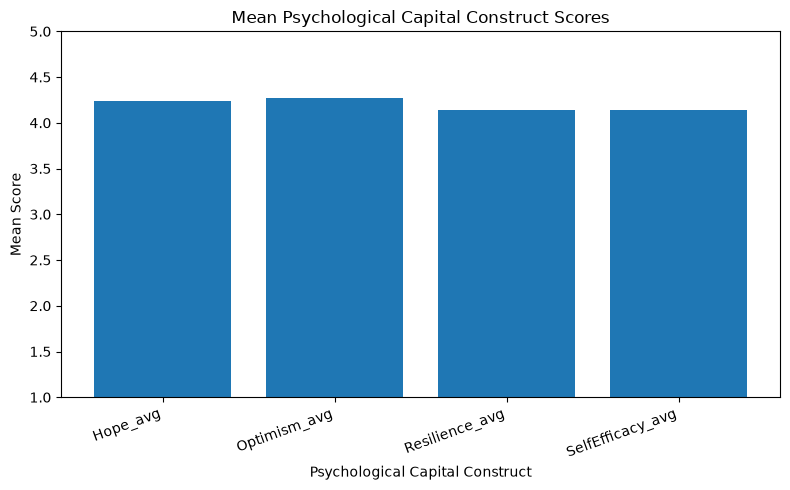

In [23]:
construct_means = (

    df[
        [
            "Hope_avg",
            "Optimism_avg",
            "Resilience_avg",
            "SelfEfficacy_avg"
        ]
    ]

    .mean()
)

plt.figure(
    figsize=(8, 5)
)

plt.bar(
    construct_means.index,
    construct_means.values
)

plt.ylabel(
    "Mean Score"
)

plt.xlabel(
    "Psychological Capital Construct"
)

plt.title(
    "Mean Psychological Capital Construct Scores"
)

plt.ylim(
    1,
    5
)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR
    / "PsyCap_Construct_Mean_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Create Final Descriptive Validation Summary

In [24]:
all_constructs_valid = bool(
    range_validation_df[
        "Within_1_to_5"
    ]
    .all()
)


no_missing_main_constructs = bool(

    df[
        MAIN_CONSTRUCTS
    ]

    .isnull()

    .sum()

    .sum()

    ==
    0
)


descriptive_validation_summary = pd.DataFrame({

    "Descriptive_Check": [

        "Required construct columns available",

        "No missing main construct values",

        "All construct scores within Likert range",

        "Descriptive statistics calculated",

        "95% confidence intervals calculated",

        "Distribution diagnostics completed",

        "Potential outliers reviewed",

        "Demographic summary completed"
    ],

    "Status": [

        (
            "PASS"
            if len(
                missing_columns
            )
            ==
            0
            else "FAIL"
        ),

        (
            "PASS"
            if no_missing_main_constructs
            else "REVIEW"
        ),

        (
            "PASS"
            if all_constructs_valid
            else "FAIL"
        ),

        "PASS",

        "PASS",

        "PASS",

        "PASS",

        "PASS"
    ]
})

descriptive_validation_summary

,Descriptive_Check,Status
0,Required construct columns available,PASS
1,No missing main construct values,PASS
2,All construct scores within Likert range,PASS
3,Descriptive statistics calculated,PASS
4,95% confidence intervals calculated,PASS
5,Distribution diagnostics completed,PASS
6,Potential outliers reviewed,PASS
7,Demographic summary completed,PASS


Save Descriptive Tables

In [25]:
final_descriptive_table.to_csv(
    REPORT_DIR
    / "Descriptive_Statistics_Summary.csv",
    index=False
)

psycap_construct_comparison.to_csv(
    REPORT_DIR
    / "PsyCap_Construct_Comparison.csv",
    index=False
)

confidence_interval_df.to_csv(
    REPORT_DIR
    / "Construct_95CI.csv",
    index=False
)

outlier_summary_df.to_csv(
    REPORT_DIR
    / "Potential_Outlier_Summary.csv",
    index=False
)

range_validation_df.to_csv(
    REPORT_DIR
    / "Construct_Range_Validation.csv",
    index=False
)

demographic_summary_df.to_csv(
    REPORT_DIR
    / "Demographic_Descriptive_Summary.csv",
    index=False
)

descriptive_validation_summary.to_csv(
    REPORT_DIR
    / "Descriptive_Validation_Summary.csv",
    index=False
)

print(
    "All descriptive reports saved successfully."
)

All descriptive reports saved successfully.


Save Data Source Summary

In [26]:
if "data_source" in df.columns:

    data_source_summary.to_csv(
        REPORT_DIR
        / "Data_Source_Descriptive_Summary.csv",
        index=False
    )

In [27]:
print(
    "PHASE 03 — STEP 03 DESCRIPTIVE STATISTICS"
)

print(
    "\nMain Construct Summary:"
)

print(

    final_descriptive_table[
        final_descriptive_table[
            "Construct"
        ]
        .isin(
            MAIN_CONSTRUCTS
        )
    ][
        [
            "Construct",
            "Mean",
            "Median",
            "Std_Dev",
            "Minimum",
            "Maximum",
            "Skewness",
            "Kurtosis",
            "CI_95_Lower",
            "CI_95_Upper"
        ]
    ]

    .to_string(
        index=False
    )
)


print(
    "\nValidation Summary:"
)

print(
    descriptive_validation_summary
    .to_string(
        index=False
    )
)

PHASE 03 — STEP 03 DESCRIPTIVE STATISTICS

Main Construct Summary:
       Construct     Mean   Median  Std_Dev  Minimum  Maximum  Skewness  Kurtosis  CI_95_Lower  CI_95_Upper
        Hope_avg 4.236000 4.333333 0.396674 1.000000      5.0 -2.653134 18.738701     4.211414     4.260586
    Optimism_avg 4.271667 4.333333 0.425101 1.000000      5.0 -2.589496 16.165332     4.245319     4.298015
  Resilience_avg 4.141000 4.333333 0.414678 1.333333      5.0 -2.166509 11.305464     4.115298     4.166702
SelfEfficacy_avg 4.139667 4.000000 0.430130 1.333333      5.0 -1.369394  7.732062     4.113007     4.166326
      PsyCap_avg 4.197083 4.250000 0.361273 1.333333      5.0 -2.678727 17.866115     4.174691     4.219475
         EVS_avg 4.083333 4.083333 0.357211 1.000000      5.0 -1.994620 12.015137     4.061193     4.105474

Validation Summary:
                       Descriptive_Check Status
    Required construct columns available   PASS
        No missing main construct values   PASS
All construc

## Step 03 නිගමනය

Phase 03 Psychological Capital සහ Employability constructs සඳහා descriptive statistical analysis සම්පූර්ණ කරන ලදී.

Constructs සඳහා mean, median, standard deviation, minimum, maximum, interquartile range, skewness සහ kurtosis ගණනය කරන ලදී. Sample mean estimates වල uncertainty පෙන්වීම සඳහා 95% confidence intervals ද ගණනය කරන ලදී.

Histograms සහ boxplots භාවිතයෙන් construct distributions සහ potential outliers පරීක්ෂා කරන ලදී. Potential outliers automatically ඉවත් නොකර, ඒවා descriptive diagnostic evidence ලෙස පමණක් සලකා බලන ලදී.

Hope, Optimism, Resilience සහ Self-Efficacy constructs අතර mean-level comparison එකක්ද සිදු කරන ලදී. Demographic variables සඳහා frequency සහ percentage summaries සකස් කරන ලදී.

මෙම descriptive analysis මගින් data distribution, variability සහ construct-level patterns පිළිබඳ මූලික අවබෝධයක් ලබාගෙන, Step 04 correlation analysis සහ ඉදිරි regression හා machine-learning experiments සඳහා දත්ත සූදානම් බව තහවුරු කරන ලදී.

1. Floor / Ceiling Effect Check

In [28]:
ceiling_floor_results = []

for column in MAIN_CONSTRUCTS:

    floor_count = (
        df[column] <= 1.5
    ).sum()

    ceiling_count = (
        df[column] >= 4.5
    ).sum()

    ceiling_floor_results.append({
        "Construct": column,
        "Floor_Count": int(floor_count),
        "Floor_Percentage": float(
            floor_count / len(df) * 100
        ),
        "Ceiling_Count": int(ceiling_count),
        "Ceiling_Percentage": float(
            ceiling_count / len(df) * 100
        )
    })

ceiling_floor_df = pd.DataFrame(
    ceiling_floor_results
)

ceiling_floor_df

,Construct,Floor_Count,Floor_Percentage,Ceiling_Count,Ceiling_Percentage
0,Hope_avg,4,0.4,181,18.1
1,Optimism_avg,6,0.6,189,18.9
2,Resilience_avg,3,0.3,66,6.6
3,SelfEfficacy_avg,2,0.2,200,20.0
4,PsyCap_avg,4,0.4,172,17.2
5,EVS_avg,1,0.1,72,7.2


Respondents ගොඩක් maximum score පැත්තට ගියොත් model එකට variation අඩු වෙනවා. Variation අඩු නම් prediction harder වෙන්න පුළුවන්.

Bootstrap Confidence Intervals

In [29]:
def bootstrap_mean_ci(
    series,
    n_bootstrap=2000,
    random_state=42
):

    rng = np.random.default_rng(
        random_state
    )

    values = (
        series
        .dropna()
        .to_numpy()
    )

    bootstrap_means = []

    for _ in range(
        n_bootstrap
    ):

        sample = rng.choice(
            values,
            size=len(values),
            replace=True
        )

        bootstrap_means.append(
            sample.mean()
        )

    return {
        "Bootstrap_Mean": float(
            np.mean(
                bootstrap_means
            )
        ),
        "CI_2.5": float(
            np.percentile(
                bootstrap_means,
                2.5
            )
        ),
        "CI_97.5": float(
            np.percentile(
                bootstrap_means,
                97.5
            )
        )
    }

In [30]:
bootstrap_descriptive_results = []

for column in MAIN_CONSTRUCTS:

    result = bootstrap_mean_ci(
        df[column]
    )

    bootstrap_descriptive_results.append({
        "Construct": column,
        **result
    })

bootstrap_descriptive_df = pd.DataFrame(
    bootstrap_descriptive_results
)

bootstrap_descriptive_df

,Construct,Bootstrap_Mean,CI_2.5,CI_97.5
0,Hope_avg,4.235957,4.210992,4.260333
1,Optimism_avg,4.272057,4.245317,4.297333
2,Resilience_avg,4.141244,4.115000,4.166000
3,SelfEfficacy_avg,4.139593,4.112667,4.166667
4,PsyCap_avg,4.197213,4.174744,4.219083
5,EVS_avg,4.083517,4.061913,4.104085


obust Descriptive Summary

In [31]:
robust_summary = pd.DataFrame({
    "Median": (
        df[MAIN_CONSTRUCTS]
        .median()
    ),
    "Q1": (
        df[MAIN_CONSTRUCTS]
        .quantile(0.25)
    ),
    "Q3": (
        df[MAIN_CONSTRUCTS]
        .quantile(0.75)
    )
})

robust_summary[
    "IQR"
] = (
    robust_summary["Q3"]
    -
    robust_summary["Q1"]
)

robust_summary

,Median,Q1,Q3,IQR
Hope_avg,4.333333,4.0,4.333333,0.333333
Optimism_avg,4.333333,4.0,4.333333,0.333333
Resilience_avg,4.333333,4.0,4.333333,0.333333
SelfEfficacy_avg,4.000000,4.0,4.333333,0.333333
PsyCap_avg,4.250000,4.0,4.333333,0.333333
EVS_avg,4.083333,4.0,4.250000,0.250000
